# CineCue: 2. Exploring the ratings

Run notebook 1 first. We explore the clean data to understand rating preferences,
popularity, and available time context. These are descriptions of the full dataset,
not model inputs. They must not be copied into Phase 2 history or popularity features.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# Work from either the repository root or its notebooks directory.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "requirements.txt").is_file(), "Open this notebook from the cloned repository."
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 20)

import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
ratings = pd.read_csv(PROCESSED / "ratings_clean.csv")
ratings["rated_at"] = pd.to_datetime(ratings["rated_at"], utc=True)
movies = pd.read_csv(PROCESSED / "movies_clean.csv")
data = ratings.merge(movies, on="movie_id", how="left", validate="many_to_one", indicator=True)
assert len(data) == len(ratings) and data["_merge"].eq("both").all()
data = data.drop(columns="_merge")

## Activity and sparsity

Our primary matrix includes users with at least one clean rating and movies with at
least one clean rating. Each user/movie pair occupies one cell even if it has repeat
events. A second denominator includes every catalog movie, including unrated movies.
There is no complete registration list in the files we use, so we do not add users
without observations. Activity counts below count events; sparsity counts unique pairs.

In [2]:
user_activity = ratings.groupby("user_id").size()
movie_activity = ratings.groupby("movie_id").size().sort_values(ascending=False)
unique_pairs = len(ratings[["user_id", "movie_id"]].drop_duplicates())
n_users, n_movies = len(user_activity), len(movie_activity)
sparsity = 1 - unique_pairs / (n_users * n_movies)
catalog_sparsity = 1 - unique_pairs / (n_users * len(movies))
top_n = int(np.ceil(0.10 * n_movies))
top_share = movie_activity.head(top_n).sum() / len(ratings)
top_one_share = movie_activity.head(1).sum() / len(ratings)
summary = {"ratings": len(ratings), "users": n_users, "rated_movies": n_movies,
           "catalog_movies": len(movies), "unique_pairs": unique_pairs,
           "user_median": float(user_activity.median()), "movie_median": float(movie_activity.median()),
           "user_min": int(user_activity.min()), "user_max": int(user_activity.max()),
           "movie_min": int(movie_activity.min()), "movie_max": int(movie_activity.max()),
           "sparsity_pct": float(100 * sparsity), "catalog_sparsity_pct": float(100 * catalog_sparsity),
           "top_10pct_movie_count": top_n, "top_10pct_share_pct": float(100 * top_share),
           "top_movie_share_pct": float(100 * top_one_share), "mean_rating": float(ratings.rating.mean())}
display(pd.Series(summary, name="value").to_frame())
display(Markdown(f"There are **{unique_pairs:,} unique pairs** in {n_users:,} × {n_movies:,} "
                 f"active user/movie cells: **{100*sparsity:.2f}% are empty**. Including all "
                 f"{len(movies):,} catalog movies gives {100*catalog_sparsity:.2f}% sparsity. "
                 "Phase 2 needs a strategy for sparse histories and movies with little feedback."))

,value
ratings,1.000209e+06
users,6.040000e+03
rated_movies,3.706000e+03
catalog_movies,3.883000e+03
unique_pairs,1.000209e+06
user_median,9.600000e+01
movie_median,1.235000e+02
user_min,2.000000e+01
user_max,2.314000e+03
movie_min,1.000000e+00


There are **1,000,209 unique pairs** in 6,040 × 3,706 active user/movie cells: **95.53% are empty**. Including all 3,883 catalog movies gives 95.74% sparsity. Phase 2 needs a strategy for sparse histories and movies with little feedback.

,count,percentage
rating,,
1,56174,5.62
2,107557,10.75
3,261197,26.11
4,348971,34.89
5,226310,22.63


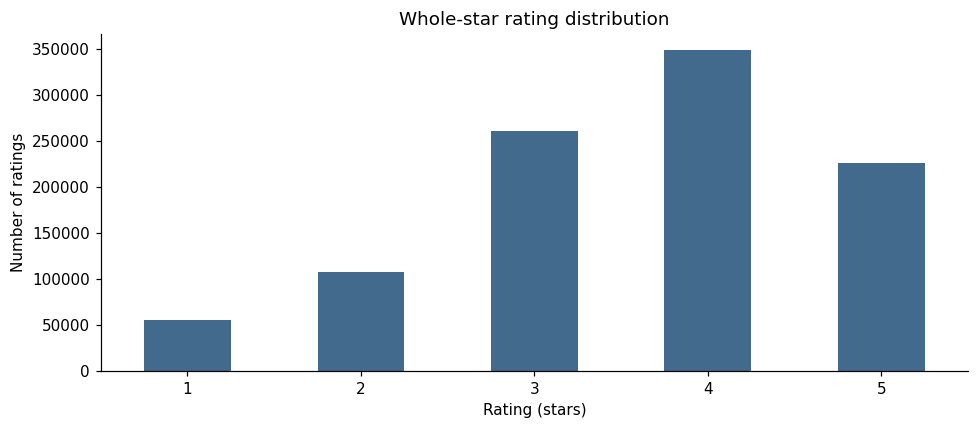

**Interpretation:** 57.52% of ratings are 4 or 5, with an overall mean of 3.582/5. Phase 2 should compare against a simple mean-rating baseline and avoid treating unobserved movies as disliked movies.

In [3]:
frequency = ratings.rating.value_counts().reindex(range(1, 6), fill_value=0).sort_index()
rating_table = pd.DataFrame({"count": frequency, "percentage": 100 * frequency / len(ratings)})
rating_table.index.name = "rating"
display(rating_table.round(2))
ax = frequency.plot.bar(color="#426a8c", rot=0)
ax.set(xlabel="Rating (stars)", ylabel="Number of ratings", title="Whole-star rating distribution")
plt.tight_layout()
plt.show()
high_pct = float(rating_table.loc[[4, 5], "percentage"].sum())
summary["rating_4_or_5_pct"] = high_pct
summary["rating_frequency"] = {str(k): {"count": int(frequency[k]),
    "percentage": float(rating_table.loc[k, "percentage"])} for k in frequency.index}
display(Markdown(f"**Interpretation:** {high_pct:.2f}% of ratings are 4 or 5, with an overall mean "
                 f"of {ratings.rating.mean():.3f}/5. Phase 2 should compare against a simple "
                 "mean-rating baseline and avoid treating unobserved movies as disliked movies."))

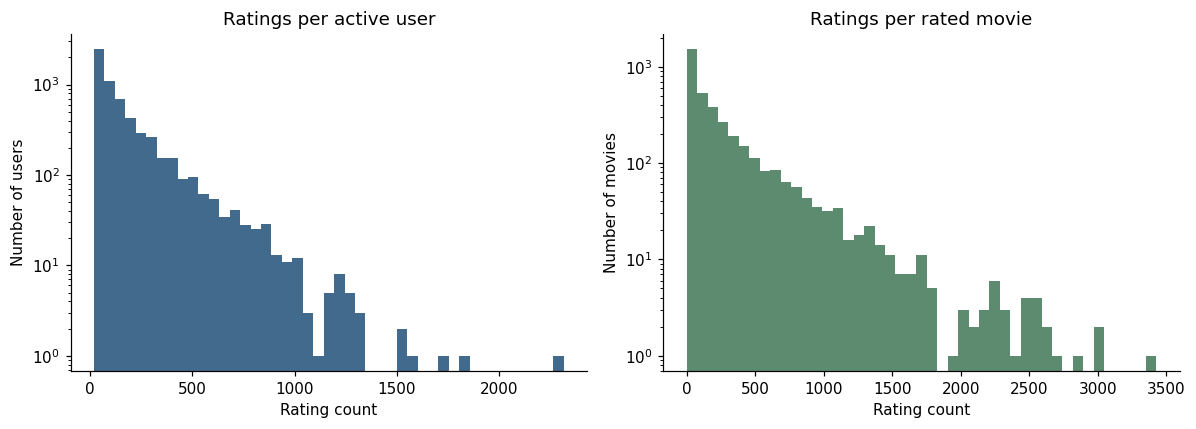

**Interpretation:** A user has a median of 96.0 ratings (range 20–2,314); a rated movie has a median of 123.5 (range 1–3,428). The log count axes make the tails visible. Keep these valid active users and movies; Phase 2 should check results separately for short histories and infrequent movies.

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(user_activity, bins=45, color="#426a8c")
axes[0].set(title="Ratings per active user", xlabel="Rating count", ylabel="Number of users", yscale="log")
axes[1].hist(movie_activity, bins=45, color="#5c8b70")
axes[1].set(title="Ratings per rated movie", xlabel="Rating count", ylabel="Number of movies", yscale="log")
plt.tight_layout()
plt.show()
display(Markdown(f"**Interpretation:** A user has a median of {user_activity.median():.1f} ratings "
                 f"(range {user_activity.min():,}–{user_activity.max():,}); a rated movie has "
                 f"a median of {movie_activity.median():.1f} (range {movie_activity.min():,}–{movie_activity.max():,}). "
                 "The log count axes make the tails visible. Keep these valid active users and movies; "
                 "Phase 2 should check results separately for short histories and infrequent movies."))

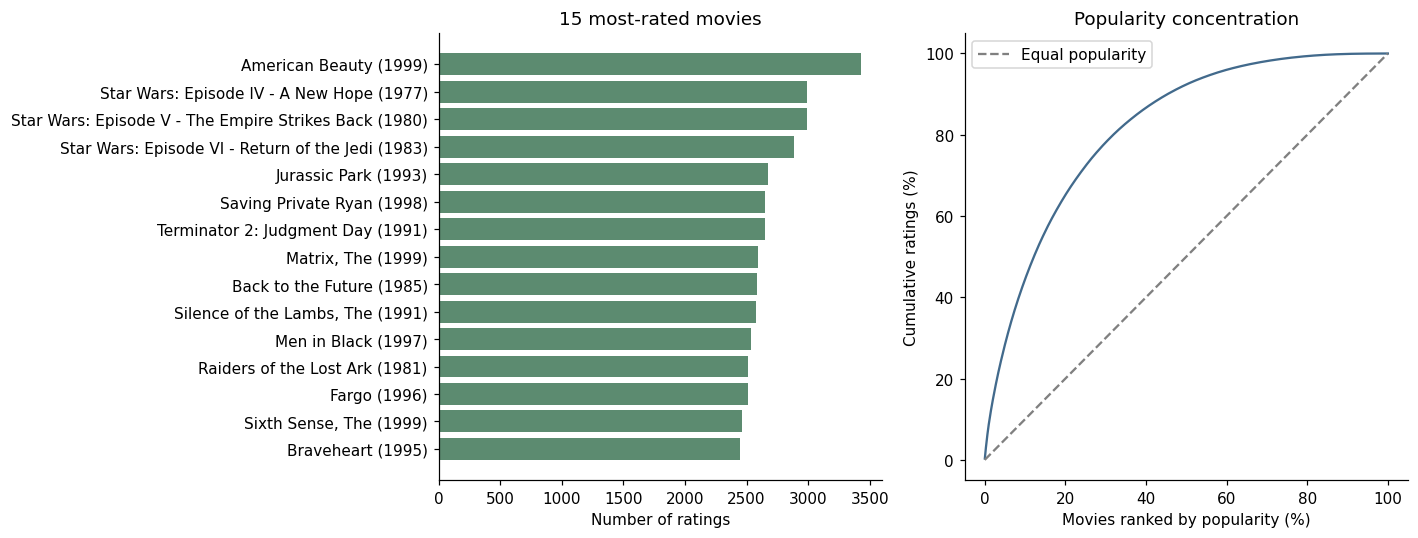

**Interpretation:** The top 371 movies (the rounded-up top 10% of rated movies) receive 44.45% of rating events. The most-rated movie, American Beauty (1999), has 3,428 ratings. This concentration can favor popular titles in Phase 2; compare coverage across popularity groups.

In [5]:
popular = movie_activity.head(15).rename("rating_count").reset_index().merge(
    movies[["movie_id", "title"]], on="movie_id", validate="one_to_one")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(popular.title.iloc[::-1], popular.rating_count.iloc[::-1], color="#5c8b70")
axes[0].set(title="15 most-rated movies", xlabel="Number of ratings")
rank_fraction = np.arange(1, n_movies + 1) / n_movies
cumulative_share = movie_activity.cumsum() / len(ratings)
axes[1].plot(100 * rank_fraction, 100 * cumulative_share, color="#426a8c")
axes[1].plot([0, 100], [0, 100], linestyle="--", color="grey", label="Equal popularity")
axes[1].set(title="Popularity concentration", xlabel="Movies ranked by popularity (%)", ylabel="Cumulative ratings (%)")
axes[1].legend()
plt.tight_layout()
plt.show()
summary["most_rated_title"] = str(popular.title.iloc[0])
display(Markdown(f"**Interpretation:** The top {top_n:,} movies (the rounded-up top 10% of rated movies) "
                 f"receive {100*top_share:.2f}% of rating events. The most-rated movie, "
                 f"{popular.title.iloc[0]}, has {popular.rating_count.iloc[0]:,} ratings. "
                 "This concentration can favor popular titles in Phase 2; compare coverage across popularity groups."))

## Genres

Catalog frequency counts movies. Rating-by-genre counts rating events. A multigenre
movie belongs to each of its genres, so one movie or interaction can count in several
groups. These groups overlap and do not sum to the number of movies or ratings.
Genre means are descriptive associations, not evidence that a genre causes higher ratings.

,rating_count,mean_rating
genre,,
Horror,76386,3.215
Children's,72186,3.422
Fantasy,36301,3.447
Sci-Fi,157294,3.467
Adventure,133953,3.477
Action,257457,3.491
Comedy,356580,3.522
Thriller,189680,3.570
Romance,147523,3.607


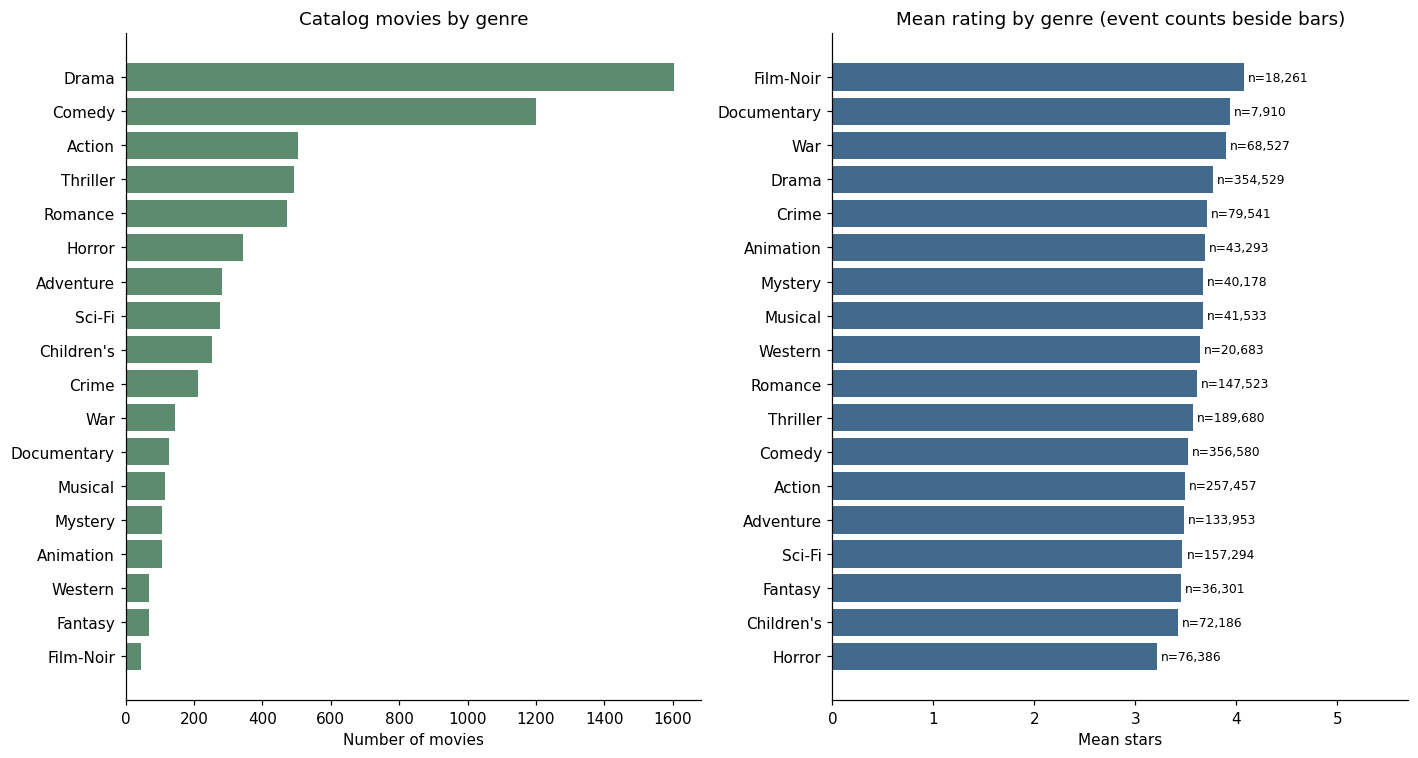

**Interpretation:** Drama is the largest catalog genre with 1,603 movies. Mean ratings range from 3.215 for Horror (n=76,386) to 4.075 for Film-Noir (n=18,261). Phase 2 can use multihot genre flags, but these full-data means must stay out of model features.

In [6]:
catalog_genres = movies.assign(genre=movies.genres.str.split("|")).explode("genre")
genre_frequency = catalog_genres.genre.value_counts().sort_values()
genre_events = data[["rating", "genres"]].assign(genre=data.genres.str.split("|")).explode("genre")
genre_stats = genre_events.groupby("genre").rating.agg(rating_count="size", mean_rating="mean").sort_values("mean_rating")
display(genre_stats.round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 7))
axes[0].barh(genre_frequency.index, genre_frequency, color="#5c8b70")
axes[0].set(title="Catalog movies by genre", xlabel="Number of movies")
axes[1].barh(genre_stats.index, genre_stats.mean_rating, color="#426a8c")
axes[1].set(title="Mean rating by genre (event counts beside bars)", xlabel="Mean stars", xlim=(0, 5.7))
for y, row in enumerate(genre_stats.itertuples()):
    axes[1].text(row.mean_rating + 0.04, y, f"n={row.rating_count:,}", va="center", fontsize=8)
plt.tight_layout()
plt.show()
best_genre, low_genre = genre_stats.index[-1], genre_stats.index[0]
summary["genre_stats"] = {str(g): {"rating_count": int(row.rating_count), "mean_rating": float(row.mean_rating)}
                          for g, row in genre_stats.iterrows()}
summary["largest_catalog_genre"] = str(genre_frequency.index[-1])
display(Markdown(f"**Interpretation:** {genre_frequency.index[-1]} is the largest catalog genre "
                 f"with {genre_frequency.iloc[-1]:,} movies. Mean ratings range from "
                 f"{genre_stats.loc[low_genre, 'mean_rating']:.3f} for {low_genre} "
                 f"(n={genre_stats.loc[low_genre, 'rating_count']:,}) to "
                 f"{genre_stats.loc[best_genre, 'mean_rating']:.3f} for {best_genre} "
                 f"(n={genre_stats.loc[best_genre, 'rating_count']:,}). Phase 2 can use multihot "
                 "genre flags, but these full-data means must stay out of model features."))

## Rating activity in UTC

The timestamps record when users submitted ratings. They do not directly record
watch times, local time zones, moods, or viewing sessions. Hour and weekday features
therefore describe UTC rating activity, with limited evidence about viewing context.

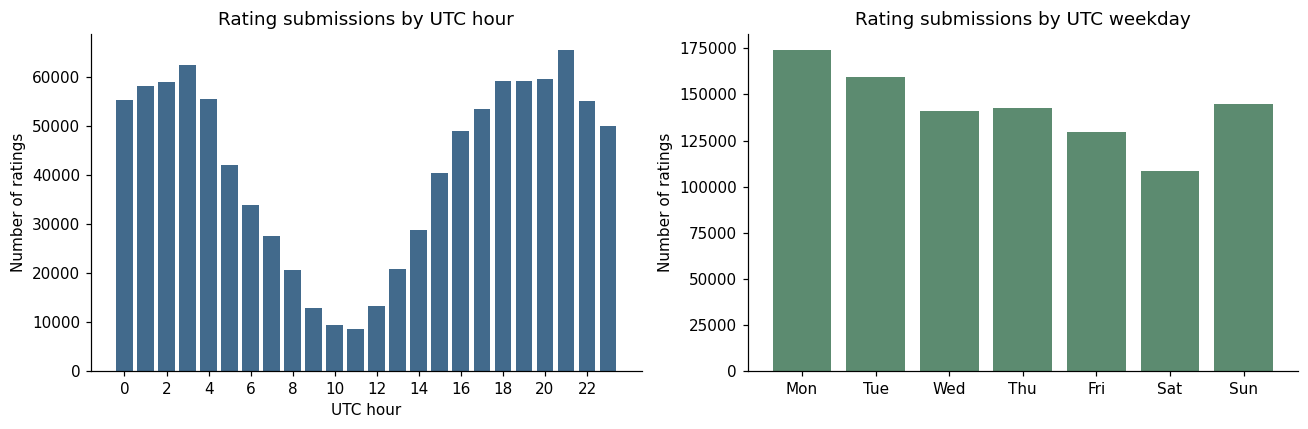

**Interpretation:** The busiest UTC hour is 21:00 with 65,491 ratings (6.55%); Monday has the most submissions (173,931). Weekend submissions account for 25.36%. All 24 UTC hours are represented, but uneven counts mean Phase 2 should check context coverage and avoid interpreting these as local viewing habits.

2905

In [7]:
hours = data.rated_at.dt.hour.value_counts().reindex(range(24), fill_value=0).sort_index()
weekdays = data.rated_at.dt.dayofweek.value_counts().reindex(range(7), fill_value=0).sort_index()
weekday_names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(hours.index, hours, color="#426a8c")
axes[0].set(title="Rating submissions by UTC hour", xlabel="UTC hour", ylabel="Number of ratings", xticks=range(0, 24, 2))
axes[1].bar(range(7), weekdays, color="#5c8b70")
axes[1].set(title="Rating submissions by UTC weekday", ylabel="Number of ratings")
axes[1].set_xticks(range(7), [day[:3] for day in weekday_names])
plt.tight_layout()
plt.show()
peak_hour = int(hours.idxmax())
peak_day = int(weekdays.idxmax())
weekend_pct = float(100 * weekdays.loc[[5, 6]].sum() / len(ratings))
summary.update({"peak_hour_utc": peak_hour, "peak_hour_count": int(hours.max()),
                "peak_weekday_utc": weekday_names[peak_day], "peak_weekday_count": int(weekdays.max()),
                "weekend_pct": weekend_pct, "hours_with_ratings": int(hours.gt(0).sum())})
display(Markdown(f"**Interpretation:** The busiest UTC hour is {peak_hour:02d}:00 "
                 f"with {hours.max():,} ratings ({100*hours.max()/len(ratings):.2f}%); "
                 f"{weekday_names[peak_day]} has the most submissions ({weekdays.max():,}). "
                 f"Weekend submissions account for {weekend_pct:.2f}%. "
                 f"All {hours.gt(0).sum()} UTC hours are represented, but uneven counts mean "
                 "Phase 2 should check context coverage and avoid interpreting these as local viewing habits."))
(PROCESSED / "eda_summary.json").write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")

## What this means for Phase 2

We have a sparse, unevenly rated catalog and a positive rating skew. A future model
should be compared with a simple baseline and checked for cold-start behavior and
popularity bias. Genre flags offer basic content information; UTC submission time
offers a limited context signal. Nothing here establishes causality.

We omit a correlation heatmap: raw IDs are labels, Unix seconds are an encoding of
time, and hour/weekday are cyclic categories. A matrix of these values would be
misleading. No full-data user or movie aggregates are passed to preprocessing.